In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import AdaBoostRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [3]:
df = pd.read_excel('final_dataset.xlsx')

In [4]:
train = df[
    (df['Season'] >= 2013) & (df['Season'] <= 2021)
    ].copy()
test  = df[df['Season'].isin([2022, 2023])].copy()

# Pull out the dependent variable 'PPG'
y_train = train['PPG']
y_test  = test['PPG']

# Drop the target and ID columns from the feature sets
drop_cols = ['PPG', 'Rk', 'Team', 'Season']
X_train = train.drop(columns=drop_cols)
X_test  = test.drop(columns=drop_cols)



In [5]:
# Define the base estimator (DecisionTreeRegressor) without preset parameters so they can be tuned
base_tree = DecisionTreeRegressor()

# Instantiate the AdaBoost regressor with the base estimator
ada = AdaBoostRegressor(estimator=base_tree, random_state=42)

# Specify a parameter grid for RandomizedSearchCV including parameters for both AdaBoost and its base estimator
param_distributions = {
    'n_estimators': [50, 100, 150, 200, 250, 300],
    'learning_rate': [0.5, 1, 1.5, 2, 3],
    'estimator__max_depth': [1, 3, 5, 7, 9, 11],
    'estimator__min_samples_split': [2, 5, 10, 15, 20]
}

# Set up the RandomizedSearchCV with 5-fold CV and MAE as the scoring metric (using neg_mean_absolute_error)
random_search = RandomizedSearchCV(
    estimator=ada,
    param_distributions=param_distributions,
    n_iter=1000,
    scoring='neg_mean_absolute_error',
    cv=5,
    random_state=42,
    n_jobs=-1
)


# Execute the random search on the training data
random_search.fit(X_train, y_train)
best_model = random_search.best_estimator_
print("Best Parameters:", random_search.best_params_)

# Evaluate the tuned model on the test set using MAE and R-squared
y_pred = best_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (Test):", mae)
print("R² Score (Test):", r2)


In [6]:
ada_best = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=11, min_samples_split=10, random_state=42),
    n_estimators=250,
    learning_rate=2,
    random_state=42
)

ada_best.fit(X_train, y_train)
y_pred_ada = ada_best.predict(X_test)
mae_ada = mean_absolute_error(y_test, y_pred_ada)
r2_ada = r2_score(y_test, y_pred_ada)

print("AdaBoost Mean Absolute Error (Test):", mae_ada)
print("AdaBoost R² Score (Test):", r2_ada)

AdaBoost Mean Absolute Error (Test): 0.09768617723150252
AdaBoost R² Score (Test): 0.8179537633009839


In [7]:

n = X_test.shape[0]
p = X_test.shape[1]

adj_r2_ada = 1 - (1 - r2_ada) * (n - 1) / (n - p - 1)
print("Adjusted R² Score (Test):", adj_r2_ada)

Adjusted R² Score (Test): 0.7701666261674922


Adjusted R² Score (Test): 0.7701666261674922

In [8]:
rf_model = RandomForestRegressor(random_state=42)

# Define the parameter grid to search
param_distributions_rf = {
    'n_estimators': [50, 75, 100, 125, 150, 200],
    'max_depth': [None, 20, 30, 40, 50, 60, 70],
    'max_features': ['sqrt', 'log2'],
    'min_samples_split': [2, 3, 5, 7, 10],
    'min_samples_leaf': [1, 2, 3, 4],
    'bootstrap': [True, False]
}

# Set up the RandomizedSearchCV object with 5-fold cross validation
rf_random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_distributions_rf,
    n_iter=1000,
    scoring='neg_mean_absolute_error',
    cv=5,
    random_state=42,
    n_jobs=-1
)

# Execute the random search on the training data
rf_random_search.fit(X_train, y_train)
best_rf_model = rf_random_search.best_estimator_
print("Best Random Forest Parameters:", rf_random_search.best_params_)


# Evaluate the tuned Random Forest model on the test set
y_pred_rf = best_rf_model.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Mean Absolute Error (Test):", mae_rf)
print("Random Forest R² Score (Test):", r2_rf)


In [9]:
# Update the model to use the best parameters
rf_best = RandomForestRegressor(
    n_estimators=200,
    min_samples_split=3,
    min_samples_leaf=1,
    max_features='sqrt',
    max_depth=40,
    bootstrap=False,
    random_state=42
)

rf_best.fit(X_train, y_train)
y_pred_rf = rf_best.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Mean Absolute Error (Test):", mae_rf)
print("Random Forest R² Score (Test):", r2_rf)


Random Forest Mean Absolute Error (Test): 0.10338201472544356
Random Forest R² Score (Test): 0.8119817242198104


In [10]:
n = X_test.shape[0]      # number of samples
p = X_test.shape[1]      # number of features

adj_r2_rf = 1 - (1 - r2_rf) * (n - 1) / (n - p - 1)
print("Adjusted R² Score (Test):", adj_r2_rf)

Adjusted R² Score (Test): 0.7626269268275107


Adjusted R² Score (Test): 0.7626269268275107

In [11]:
# Scale the data (if not already scaled)
scaler_nn = StandardScaler()
X_train_nn = scaler_nn.fit_transform(X_train)
X_test_nn  = scaler_nn.transform(X_test)



# Build the MLP model
model = Sequential()
model.add(Dense(128, activation='relu', input_shape=(X_train_nn.shape[1],)))
model.add(Dropout(0.3))  # Helps prevent overfitting on small datasets
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='linear'))  # Linear activation for regression

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mean_absolute_error',  # MAE as the loss function since performance is measured with MAE
    metrics=['mean_absolute_error']
)

# Set up callbacks for early stopping and learning rate reduction
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=10,
    min_lr=1e-6
)

# Train the model. Using validation_split since the dataset is small.
history = model.fit(
    X_train_nn,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=16,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# Evaluate on the test set
y_pred_nn = model.predict(X_test_nn).flatten()  # flatten in case of (n,1) shape
mae_nn = mean_absolute_error(y_test, y_pred_nn)
r2_nn = r2_score(y_test, y_pred_nn)

Epoch 1/200


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.6094 - mean_absolute_error: 0.6094 - val_loss: 0.3594 - val_mean_absolute_error: 0.3594 - learning_rate: 0.0010
Epoch 2/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3299 - mean_absolute_error: 0.3299 - val_loss: 0.2455 - val_mean_absolute_error: 0.2455 - learning_rate: 0.0010
Epoch 3/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2900 - mean_absolute_error: 0.2900 - val_loss: 0.2413 - val_mean_absolute_error: 0.2413 - learning_rate: 0.0010
Epoch 4/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2553 - mean_absolute_error: 0.2553 - val_loss: 0.2704 - val_mean_absolute_error: 0.2704 - learning_rate: 0.0010
Epoch 5/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2280 - mean_absolute_error: 0.2280 - val_loss: 0.1993 - val_mean_absolute_error: 0.1993 - learning_rate: 0.0010
Epoch 6/200
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2342 - mean_absolute_error: 0.2342 - val_loss: 0.2253 - val_mean_absolute_error: 0.225

In [12]:

print("Neural Network Mean Absolute Error (Test):", mae_nn)
print("Neural Network R² Score (Test):", r2_nn)

Neural Network Mean Absolute Error (Test): 0.1074415304884025
Neural Network R² Score (Test): 0.8106843726710071


Adjusted R² Score (Test): 0.7290011993901999

In [13]:
n = X_test.shape[0]      # number of samples
p = X_test.shape[1]      # number of features

adj_r2_nn = 1 - (1 - r2_nn) * (n - 1) / (n - p - 1)
print("Adjusted R² Score (Test):", adj_r2_nn)

Adjusted R² Score (Test): 0.7609890204971465


Random Forest Permutation Importances (mean over 10 repeats):
+/-                 0.628091
GWG                 0.112002
A                   0.035942
coach_ppg           0.021166
GA                  0.008750
tenure              0.006492
G                   0.006119
FOL                 0.004915
Shots               0.004761
PIM                 0.002677
Blk                 0.002580
SO                  0.002443
Rank                0.002299
power_play_goals    0.002165
GP                  0.001854
SHG                 0.000594
Min_Decimal        -0.000090
Category           -0.000308
Latitude           -0.000498
Sv                 -0.001502
FOW                -0.001762
dtype: float64


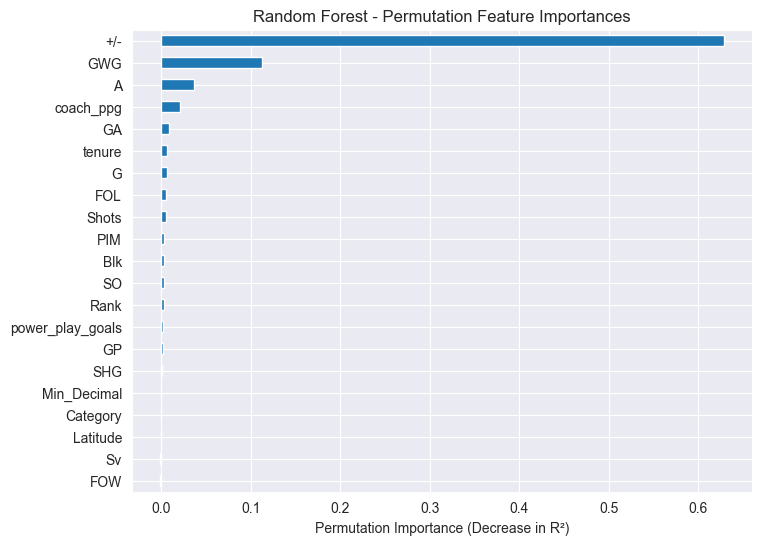

In [14]:
# --- Permutation Importance ---
# Calculate permutation importance on the test set (using r² as scoring)
perm_importance = permutation_importance(
    rf_best, X_test, y_test, scoring='r2', n_repeats=10, random_state=42
)

# Create a Series for permutation importance mean values
perm_importances = pd.Series(perm_importance.importances_mean, index=X_test.columns)
perm_importances = perm_importances.sort_values(ascending=False)
print("Random Forest Permutation Importances (mean over 10 repeats):")
print(perm_importances)

# Plot permutation importance
plt.figure(figsize=(8, 6))
perm_importances.plot(kind='barh')
plt.xlabel("Permutation Importance (Decrease in R²)")
plt.title("Random Forest - Permutation Feature Importances")
plt.gca().invert_yaxis()  # Highest importance at the top
plt.show()

Random Forest Mean Decrease in Impurity (MDI) Importances:
+/-                 0.368935
GWG                 0.152286
A                   0.065510
GA                  0.051514
coach_ppg           0.045995
G                   0.039805
FOL                 0.033416
GP                  0.025905
Shots               0.024905
Blk                 0.024480
SO                  0.022991
PIM                 0.022055
FOW                 0.018785
Min_Decimal         0.018633
Sv                  0.018192
tenure              0.017672
Rank                0.014226
Latitude            0.013004
power_play_goals    0.012926
SHG                 0.005821
Category            0.002943
dtype: float64


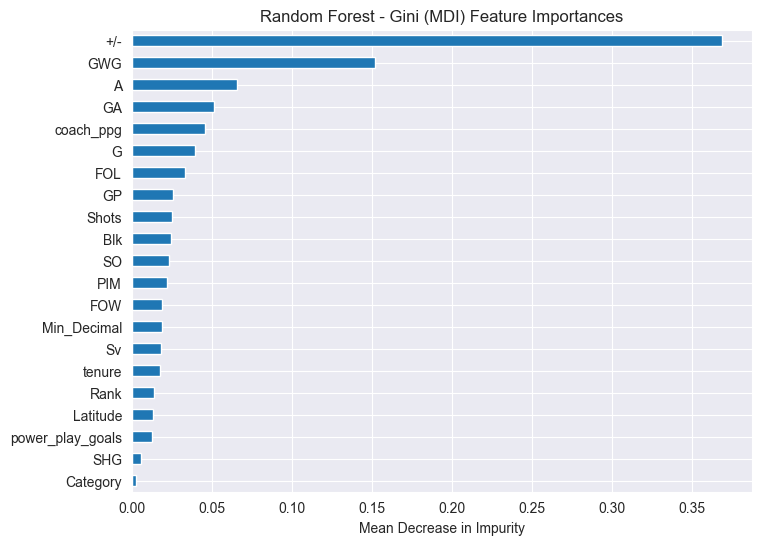

In [15]:
# --- Mean Decrease in Impurity (Gini Importance) ---
mdi_importances = pd.Series(rf_best.feature_importances_, index=X_train.columns)
mdi_importances = mdi_importances.sort_values(ascending=False)
print("Random Forest Mean Decrease in Impurity (MDI) Importances:")
print(mdi_importances)

# Plot MDI feature importances
plt.figure(figsize=(8, 6))
mdi_importances.plot(kind='barh')
plt.xlabel("Mean Decrease in Impurity")
plt.title("Random Forest - Gini (MDI) Feature Importances")
plt.gca().invert_yaxis()  # Highest importance at the top
plt.show()


AdaBoost Feature Importances:
+/-                 0.714754
GWG                 0.100276
A                   0.017482
Shots               0.017008
Blk                 0.015682
coach_ppg           0.015325
GP                  0.014835
FOL                 0.013040
GA                  0.011843
tenure              0.011706
Rank                0.009712
Latitude            0.009378
PIM                 0.009008
power_play_goals    0.006505
Min_Decimal         0.006425
Sv                  0.006403
FOW                 0.005780
G                   0.005150
SO                  0.004344
SHG                 0.003331
Category            0.002014
dtype: float64


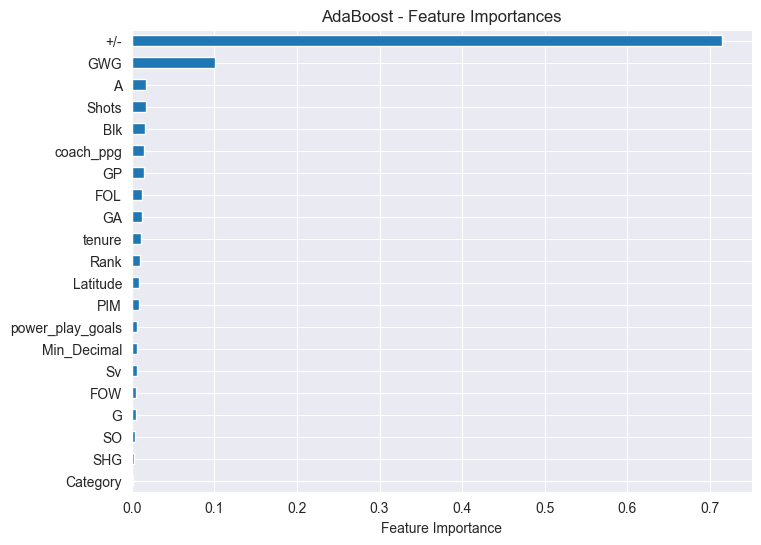

In [16]:

feature_importances = pd.Series(ada_best.feature_importances_, index=X_train.columns)

# Sort the importances in descending order
sorted_importances = feature_importances.sort_values(ascending=False)
print("AdaBoost Feature Importances:")
print(sorted_importances)

# Optionally, visualize the feature importances using a horizontal bar chart
plt.figure(figsize=(8, 6))
sorted_importances.plot(kind='barh')
plt.xlabel("Feature Importance")
plt.title("AdaBoost - Feature Importances")
plt.gca().invert_yaxis()  # highest importance at the top
plt.show()


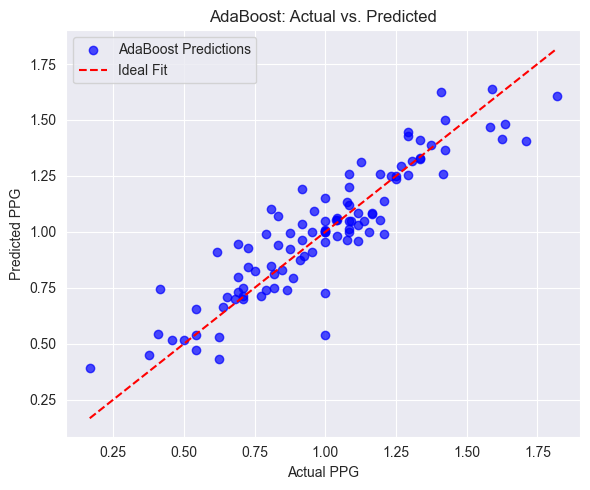

In [17]:
all_values = np.concatenate([y_test, y_pred_ada, y_pred_rf])
min_val, max_val = all_values.min(), all_values.max()

# AdaBoost plot
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_ada, alpha=0.7, label='AdaBoost Predictions', color='b')
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit')
plt.xlabel("Actual PPG")
plt.ylabel("Predicted PPG")
plt.title("AdaBoost: Actual vs. Predicted")
plt.legend()
plt.tight_layout()
plt.show()

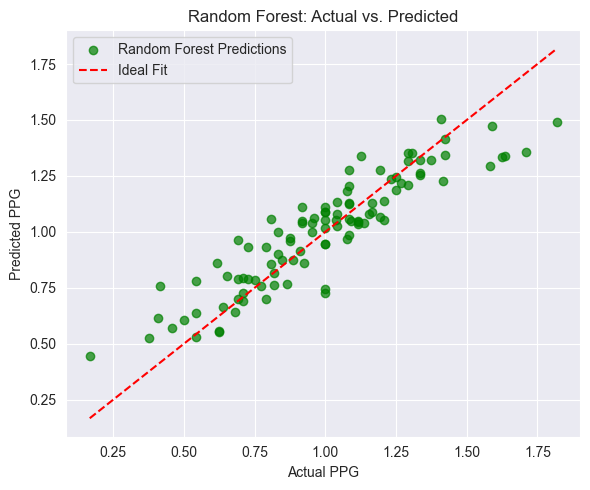

In [18]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_rf, alpha=0.7, label='Random Forest Predictions', color='g')
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit')
plt.xlabel("Actual PPG")
plt.ylabel("Predicted PPG")
plt.title("Random Forest: Actual vs. Predicted")
plt.legend()
plt.tight_layout()
plt.show()

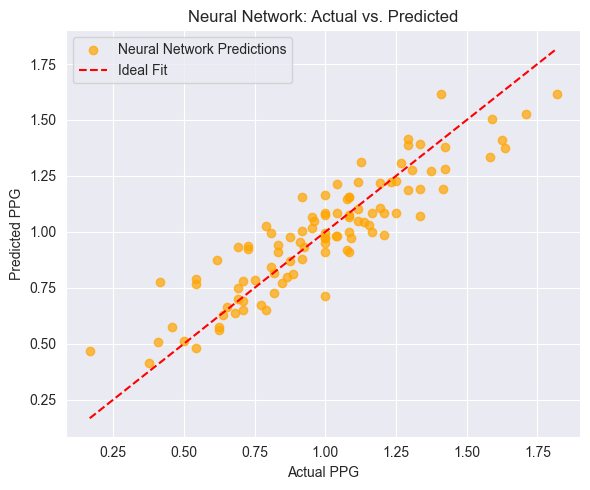

In [19]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_nn, alpha=0.7, label='Neural Network Predictions', color='orange')
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit')
plt.xlabel("Actual PPG")
plt.ylabel("Predicted PPG")
plt.title("Neural Network: Actual vs. Predicted")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# Compute baseline r² score using the neural network model
y_pred_nn = model.predict(X_test_nn).flatten()
baseline_score = r2_score(y_test, y_pred_nn)

# Set number of shuffling repeats for stability
n_repeats = 10
importances = []

# Loop over each feature (assumes X_test_nn is a NumPy array)
for i in range(X_test_nn.shape[1]):
    scores = []
    for _ in range(n_repeats):
        X_permuted = X_test_nn.copy()
        # Shuffle the values in column i
        np.random.shuffle(X_permuted[:, i])
        # Compute r² score after permuting this feature
        permuted_score = r2_score(y_test, model.predict(X_permuted).flatten())
        scores.append(baseline_score - permuted_score)
    # Average decrease in r² over repeats gives the feature importance
    importances.append(np.mean(scores))

# Map computed importances back to feature names from the original test set
feature_names = X_test.columns  # Ensure X_test is your original DataFrame with feature names
perm_importances_nn = pd.Series(importances, index=feature_names).sort_values(ascending=False)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


Neural Network Permutation Importances (Decrease in R²):
+/-                 0.766340
GWG                 0.149227
GA                  0.105064
A                   0.066911
Sv                  0.026075
SO                  0.022584
Min_Decimal         0.019724
coach_ppg           0.019276
Shots               0.016191
power_play_goals    0.013110
SHG                 0.012991
GP                  0.010315
Blk                 0.009120
FOL                 0.008158
Category            0.007496
PIM                 0.007412
tenure              0.006785
FOW                 0.004748
G                   0.004624
Rank                0.002026
Latitude            0.000264
dtype: float64


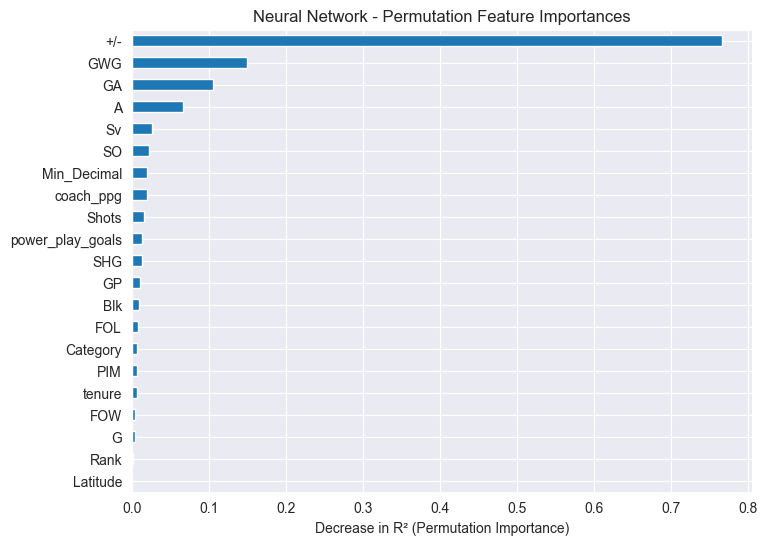

In [21]:

print("Neural Network Permutation Importances (Decrease in R²):")
print(perm_importances_nn)

# Plot the permutation importances as a horizontal bar chart
plt.figure(figsize=(8, 6))
perm_importances_nn.plot(kind='barh')
plt.xlabel("Decrease in R² (Permutation Importance)")
plt.title("Neural Network - Permutation Feature Importances")
plt.gca().invert_yaxis()  # Highest importance at the top
plt.show()

# Create a new training data version using only the '+/-' and 'GWG' columns
X_train_new = X_train[['+/-', 'GWG']]


# Execute the random search on the new training data
random_search.fit(X_train_new, y_train)
best_model = random_search.best_estimator_
print("Best Parameters:", random_search.best_params_)


est Parameters: {'n_estimators': 50, 'learning_rate': 1, 'estimator__min_samples_split': 2, 'estimator__max_depth': 3}

NameError: name 'X_train_new' is not defined

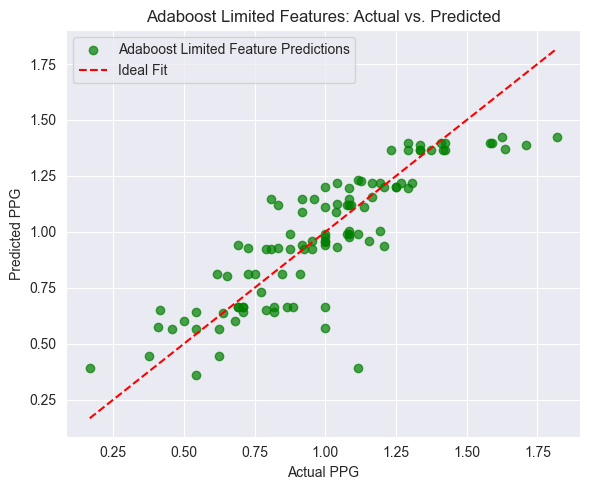

In [23]:

feature_importances = pd.Series(ada_best.feature_importances_, index=X_train_new.columns)

# Sort the importances in descending order
sorted_importances = feature_importances.sort_values(ascending=False)
print("AdaBoost Feature Importances:")
print(sorted_importances)

# Optionally, visualize the feature importances using a horizontal bar chart
plt.figure(figsize=(8, 6))
sorted_importances.plot(kind='barh')
plt.xlabel("Feature Importance")
plt.title("AdaBoost - Feature Importances")
plt.gca().invert_yaxis()  # highest importance at the top
plt.show()


AttributeError: 'AdaBoostRegressor' object has no attribute 'estimators_'

In [24]:
# Create a new training data version using only the '+/-' and 'GWG' columns
X_train_limited = X_train[['+/-', 'GWG', 'coach_ppg', 'A', 'Shots', 'GA']]



# Execute the random search on the new training data
random_search.fit(X_train_limited, y_train)
best_model = random_search.best_estimator_
print("Best Parameters:", random_search.best_params_)


In [25]:
best_model = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=5, min_samples_split=20, random_state=42),
    n_estimators=100,
    learning_rate=1.5,
    random_state=42
)

In [26]:
best_model.fit(X_train_limited, y_train)
X_test_limited = X_test[['+/-', 'GWG', 'coach_ppg', 'A', 'Shots', 'GA']]

In [42]:

y_pred_limited = best_model.predict(X_test_limited)
mae_lim = mean_absolute_error(y_test, y_pred_limited)
r2_lim = r2_score(y_test, y_pred_limited)



print("Mean Absolute Error (Test):", mae)
print("R² Score (Test):", r2_lim)


Mean Absolute Error (Test): 0.10630544729612837
R² Score (Test): 0.7977465000748815


In [28]:
n = X_test_limited.shape[0]      # number of samples
p = X_test_limited.shape[1]      # number of features

adj_r2_lim = 1 - (1 - r2_lim) * (n - 1) / (n - p - 1)
print("Adjusted R² Score (Test):", adj_r2_lim)

Adjusted R² Score (Test): 0.784972594816453


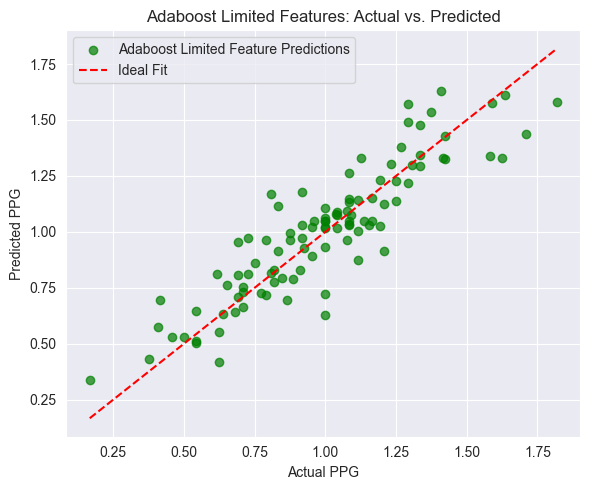

In [29]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred_limited, alpha=0.7, label='Adaboost Limited Feature Predictions', color='g')
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Ideal Fit')
plt.xlabel("Actual PPG")
plt.ylabel("Predicted PPG")
plt.title("Adaboost Limited Features: Actual vs. Predicted")
plt.legend()
plt.tight_layout()
plt.show()

AdaBoost Feature Importances (Limited Feature Model):
+/-          0.771876
GWG          0.082793
Shots        0.047865
GA           0.034664
coach_ppg    0.034556
A            0.028246
dtype: float64


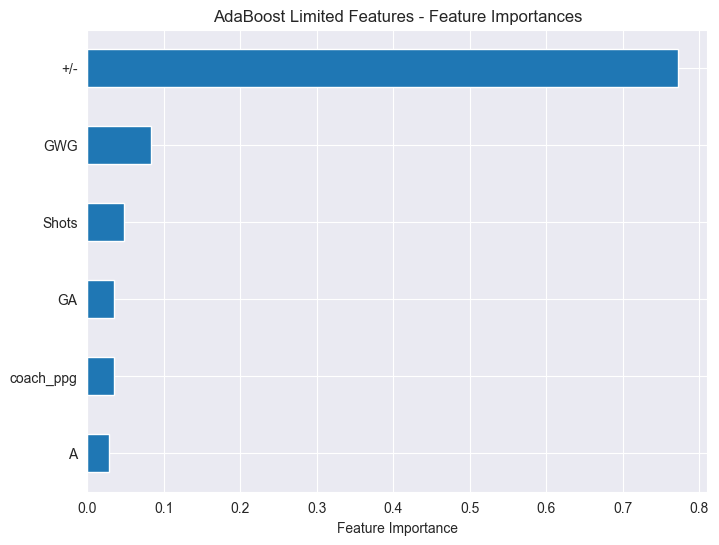

In [30]:

feature_importances = pd.Series(best_model.feature_importances_, index=X_train_limited.columns)

# Sort the importances in descending order
sorted_importances = feature_importances.sort_values(ascending=False)
print("AdaBoost Feature Importances (Limited Feature Model):")
print(sorted_importances)

# Optionally, visualize the feature importances using a horizontal bar chart
plt.figure(figsize=(8, 6))
sorted_importances.plot(kind='barh')
plt.xlabel("Feature Importance")
plt.title("AdaBoost Limited Features - Feature Importances")
plt.gca().invert_yaxis()  # highest importance at the top
plt.show()


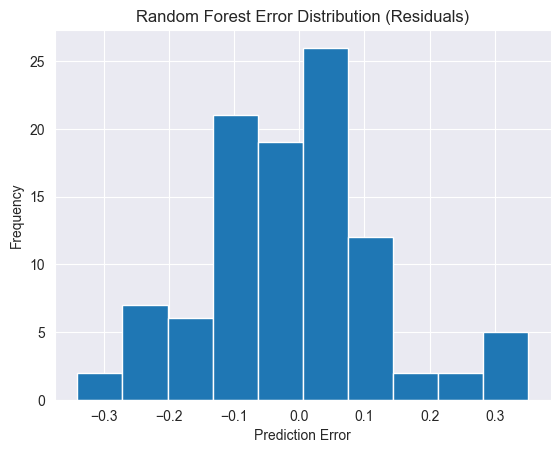

In [40]:
residuals_rf = y_test - y_pred_rf

# Plot error distribution
plt.figure()
plt.hist(residuals_rf, bins=10)
plt.title("Random Forest Error Distribution (Residuals)")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.show()

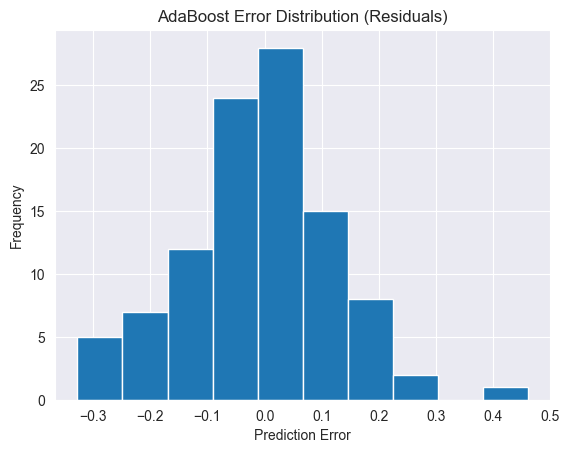

In [36]:
residuals_ada = y_test - y_pred_ada
plt.figure()
plt.hist(residuals_ada, bins=10)
plt.title("AdaBoost Error Distribution (Residuals)")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.show()

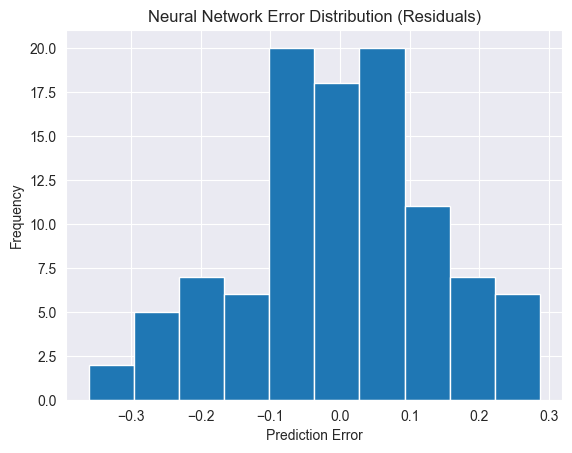

In [37]:

# Neural Network error distribution
residuals_nn = y_test - y_pred_nn
plt.figure()
plt.hist(residuals_nn, bins=10)
plt.title("Neural Network Error Distribution (Residuals)")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.show()

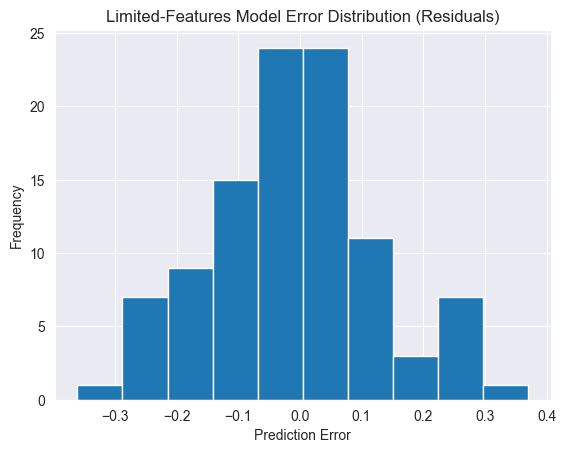

In [38]:

# Limited-features model error distribution
residuals_limited = y_test - y_pred_limited
plt.figure()
plt.hist(residuals_limited, bins=10)
plt.title("Limited-Features Model Error Distribution (Residuals)")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.show()

In [39]:
residuals_rf      = y_test - y_pred_rf
residuals_ada     = y_test - y_pred_ada
residuals_nn      = y_test - y_pred_nn
residuals_limited = y_test - y_pred_limited

for name, res in [
    ('Random Forest',      residuals_rf),
    ('AdaBoost',           residuals_ada),
    ('Neural Network',     residuals_nn),
    ('Limited-Features',   residuals_limited)
]:
    pct = np.mean(np.abs(res) <= 0.1) * 100
    print(f"{name}: {pct:.2f}% within ±0.1")

Random Forest: 65.69% within ±0.1
AdaBoost: 61.76% within ±0.1
Neural Network: 57.84% within ±0.1
Limited-Features: 59.80% within ±0.1


In [44]:

data = {
    'Model': ['Random Forest', 'AdaBoost', 'Neural Network', 'Limited-Features'],
    'MAE': [mae_rf, mae_ada, mae_nn, mae_lim],
    'R²': [r2_rf, r2_ada, r2_nn, r2_lim],
    'Adjusted R²': [adj_r2_rf, adj_r2_ada, adj_r2_nn, adj_r2_lim]
}
df_metrics = pd.DataFrame(data)

# ——— Table X ———
print(df_metrics)

              Model       MAE        R²  Adjusted R²
0     Random Forest  0.103382  0.811982     0.762627
1          AdaBoost  0.097686  0.817954     0.770167
2    Neural Network  0.107442  0.810684     0.760989
3  Limited-Features  0.106305  0.797747     0.784973


              Model       MAE        R²  Adjusted R²
0     Random Forest  0.103382  0.811982     0.762627
1          AdaBoost  0.097686  0.817954     0.770167
2    Neural Network  0.107442  0.810684     0.760989
3  Limited-Features  0.106305  0.797747     0.784973

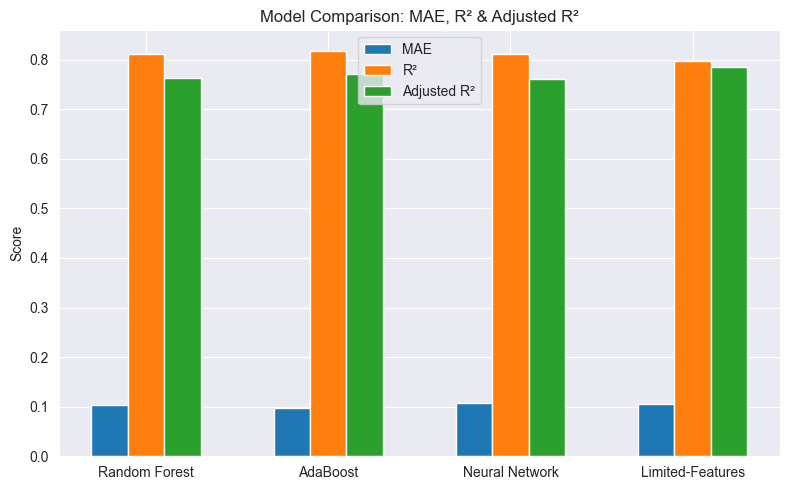

In [45]:

# ——— Bar Chart ———
df_plot = df_metrics.melt(id_vars='Model', var_name='Metric', value_name='Value')
metrics = df_plot['Metric'].unique()

x = np.arange(len(df_metrics))
width = 0.2

fig, ax = plt.subplots(figsize=(8, 5))
for i, metric in enumerate(metrics):
    vals = df_plot[df_plot['Metric']==metric]['Value']
    ax.bar(x + i*width, vals, width, label=metric)

ax.set_xticks(x + width*(len(metrics)-1)/2)
ax.set_xticklabels(df_metrics['Model'])
ax.set_ylabel('Score')
ax.set_title('Model Comparison: MAE, R² & Adjusted R²')
ax.legend()
plt.tight_layout()
plt.show()


In [47]:
X_train.describe()

,tenure,Category,Rank,Latitude,coach_ppg,GP,G,A,PIM,Shots,...,power_play_goals,SHG,GWG,Blk,FOW,FOL,GA,Sv,SO,Min_Decimal
count,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,...,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000,454.000000
mean,9.033040,0.583700,96.477974,43.404853,1.015819,319.669604,44.237885,75.944934,181.616740,476.202643,...,10.995595,1.389868,7.035242,200.198238,479.193833,484.325991,39.453744,401.325991,1.162996,902.947504
std,8.243066,0.838267,99.321376,3.854367,0.227289,64.029836,14.662676,23.278695,66.755051,121.524254,...,5.235300,1.449666,3.451792,59.124558,184.990704,181.708034,26.536764,262.399783,1.499035,577.795559
min,0.000000,0.000000,1.000000,38.846200,0.227273,123.000000,5.000000,16.000000,44.000000,126.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,28.250000,41.705600,0.892857,277.000000,34.000000,61.000000,135.000000,392.250000,...,7.000000,0.000000,5.000000,160.000000,339.500000,349.000000,14.250000,132.500000,0.000000,328.295833
50%,6.000000,0.000000,60.000000,42.386800,1.019259,321.000000,42.000000,73.000000,171.000000,463.500000,...,10.000000,1.000000,7.000000,199.000000,474.500000,480.500000,44.000000,473.000000,1.000000,1083.033333
75%,14.000000,1.000000,121.000000,44.148600,1.205195,364.000000,53.000000,89.000000,218.750000,548.500000,...,14.000000,2.000000,9.000000,240.000000,603.250000,614.500000,60.000000,616.750000,2.000000,1412.787500
max,33.000000,2.000000,392.000000,64.859100,1.708333,501.000000,95.000000,161.000000,470.000000,874.000000,...,34.000000,8.000000,19.000000,423.000000,988.000000,1037.000000,103.000000,985.000000,9.000000,1726.200000


In [48]:
X_test.describe()

,tenure,Category,Rank,Latitude,coach_ppg,GP,G,A,PIM,Shots,...,power_play_goals,SHG,GWG,Blk,FOW,FOL,GA,Sv,SO,Min_Decimal
count,102.000000,102.000000,102.000000,102.000000,102.000000,102.000000,102.000000,102.000000,102.000000,102.000000,...,102.000000,102.000000,102.000000,102.000000,102.000000,102.000000,102.000000,102.000000,102.000000,102.000000
mean,7.950980,0.598039,91.107843,42.933510,0.986633,295.000000,40.431373,70.107843,151.450980,427.421569,...,9.509804,1.264706,6.362745,179.931373,427.313725,436.549020,16.588235,168.764706,0.529412,387.410131
std,8.687509,0.847358,94.166054,2.103583,0.255310,55.996287,12.413271,22.172549,53.834846,97.380588,...,4.354911,1.371033,3.043543,49.571283,175.024240,166.223733,24.629272,250.135178,1.105395,573.132407
min,0.000000,0.000000,1.000000,38.846200,0.269231,29.000000,0.000000,4.000000,6.000000,19.000000,...,0.000000,0.000000,0.000000,18.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,28.250000,41.731075,0.858539,267.250000,32.000000,54.250000,120.000000,365.750000,...,6.000000,0.000000,4.000000,141.500000,303.000000,320.750000,0.000000,0.000000,0.000000,0.000000
50%,5.000000,0.000000,59.000000,42.556600,1.015354,300.000000,41.000000,69.000000,147.500000,420.500000,...,10.000000,1.000000,6.000000,186.000000,435.000000,451.000000,0.000000,0.000000,0.000000,0.000000
75%,10.750000,1.000000,121.000000,44.148600,1.187609,326.750000,48.000000,84.000000,173.750000,488.250000,...,13.000000,2.000000,8.000000,211.000000,558.750000,563.500000,30.500000,303.500000,0.750000,722.087500
max,35.000000,2.000000,392.000000,47.925300,1.537637,445.000000,72.000000,118.000000,358.000000,711.000000,...,20.000000,5.000000,15.000000,284.000000,860.000000,772.000000,87.000000,831.000000,6.000000,1577.750000
